Una institución financiera diseña tres opciones sobre acciones que actualmente cotizan en **$100**.

## Opción A

$$
K = 90
$$

$$
T = \frac{1}{12}
$$

**Prima = 12**

$$
\Delta = 0.85
$$

$$
\text{Vega} = 0.05
$$

$$
\Theta = -0.10
$$

## Opción B

$$
K = 100
$$

$$
T = \frac{3}{12}
$$

**Prima = 8**

$$
\Delta = 0.50
$$

$$
\text{Vega} = 0.25
$$

$$
\Theta = -0.03
$$

## Opción C

$$
K = 120
$$

$$
T = 1
$$

**Prima = 5**

$$
\Delta = 0.20
$$

$$
\text{Vega} = 0.40
$$

$$
\Theta = -0.01
$$


## Parte 1: Observación

1. ¿Cuál opción parece más sensible a cambio en el precio de la acción?
    A por el alto coeficiente de Delta, por cada peso que suba S el precio de la opcion sube 0.85
2. ¿Cuál opción parece más sensible a cambios en volatilidad?
    C con Vega de 0.4, por cada unidad porcentual que sube la volatilidad el precio sube 0.4
3. ¿Cuál opción parece deteriorarse más rápidamente con el paso del tiempo?
    A, con cada dia que pasa el precio de la accion baja 0.1 
4. ¿Cuál opción parece tener el comportamiento más parecido al de la acción?
   A, porque su Delta de 0.85 es el más cercano a 1. Esto significa que sus movimientos en precio son los más parecidos a los movimientos de la acción.
5. ¿Cuál acción parece depender más de que ocurra un evento importante en el futuro?
    C, porque tiene el Vega más alto y el mayor tiempo al vencimiento. Por lo tanto, su valor depende más de cambios futuros en la volatilidad y tiene más tiempo para que ocurra un evento importante que afecte el precio de la acción. 

## Parte 2: Escenarios de mercado 

Para cada escenario explica qué opción comprarías y cuál evitarías. Justifica tus respuestas usando tu entendimiento de sensibilidades.

Escenario A:
Piensas que la acción aumentará gradualmente durante los próximos meses. No crees que vaya a cambiar la volatilidad.
Compraría A, porque si espero que la acción suba gradualmente, su Delta de 0.85 hace que el precio de la opción responda fuertemente a los aumentos del precio de la acción. Además, su strike de 90 hace que ya se encuentre ITM.
Evitaría C, porque tiene un Delta de solo 0.20, por lo que reaccionará mucho menos ante una subida gradual del precio.

Escenario B:
Dentro de dos semanas la empresa anunciará un nuevo producto. No sabes si el precio subirá o bajará, pero esperas un cambio brusco.
Compraría C, porque tiene el Vega más alto. Si antes del anuncio aumenta la volatilidad implícita, el precio de C será el que más se beneficie.
Evitaría A, porque su Vega es únicamente 0.05 y prácticamente no se beneficia de un incremento en volatilidad.

Escenario C:
Piensas que la acción se mantendrá muy estable.
Compraría C, porque tiene el Theta menos negativo (-0.01), por lo que es la opción que pierde menos valor por el simple paso del tiempo.
Evitaría A, porque tiene el Theta más negativo (-0.10), y si la acción permanece estable, su alto Delta aporta poca ventaja mientras continúa sufriendo pérdida temporal.

Escenario D:
Crees que va a haber una caída significativa del precio de la acción
Si espero una caída significativa y por los valores de los parametros que se nos dieron asumo que no es posible comprar puts, osea que tengo que comprar una call, evitaría A, porque su Delta de 0.85 hace que sea la opción más sensible a una caída del precio de la acción. Entre las tres, C sería la menos afectada inicialmente, debido a su Delta de 0.20.
Escenario E:
Crees que el mercado está subestimando la incertidumbre futura
Compraría C, porque tiene el Vega más alto (0.40). Si el mercado está subestimando la incertidumbre futura y aumentará la volatilidad, C será la opción cuyo precio más aumentará por ese cambio.
Evitaría A, porque su Vega de 0.05 hace que su precio sea mucho menos sensible a cambios en volatilidad.

In [ ]:
S=[100,102,101,105,103,110]
vol=[0.2,0.25,0.3,0.28,0.22,0.2]
r0=0.05
K=100
Vt=[6.887]
delta=0.5977
gamma=0.02736
vega=0.2814
theta=-8.116
dt=1/12

5

In [19]:
import numpy as np
ds=np.diff(S)
dsig=np.diff(vol)

for i in range(len(ds)):
    V1=Vt[-1] + delta*ds[i] +0.5*gamma*ds[i]**2 + vega *dsig[i] + theta*dt
    Vt.append(V1)
Vt
    

[6.887,
 np.float64(7.474856666666667),
 np.float64(6.228573333333334),
 np.float64(8.156292),
 np.float64(6.322394666666667),
 np.float64(10.494653333333334)]

In [20]:
sim = 10000
calls=[]

z = np.random.normal(0, 1, sim)
for i in range(6):
    St = S[i] * np.exp(
    (r0 - 0.5 * vol[i]**2) * ((6-i)/12)
    + vol[i]* np.sqrt((6-i)/12) * z
)

    payoff = np.maximum(St - K, 0)

    call = np.exp(-r0 * ((6-i)/12)) * np.mean(payoff)
    calls.append(call)
calls

[np.float64(6.998652601956241),
 np.float64(8.797254247351097),
 np.float64(8.421884213405361),
 np.float64(9.470106904364984),
 np.float64(5.930991656843784),
 np.float64(10.58753962683041)]

In [22]:
error_abs = np.abs(np.array(Vt) - np.array(calls))
error_abs

array([0.1116526 , 1.32239758, 2.19331088, 1.3138149 , 0.39140301,
       0.09288629])

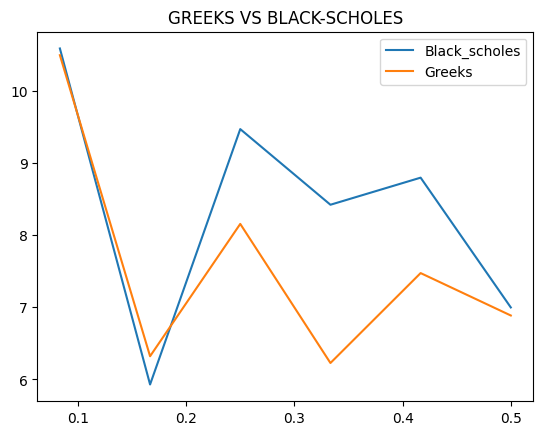

In [28]:
import matplotlib.pyplot as plt
dt=[6/12,5/12,4/12, 3/12, 2/12, 1/12]
plt.plot(dt,calls, label="Black_scholes")
plt.plot(dt,Vt, label="Greeks")
plt.title("GREEKS VS BLACK-SCHOLES")
plt.legend()

1. ¿Los greeks iniciales describen con precisión toda la trayectoria?
    Al principio parece ir bien pero al poco tiemp empieza a diferir mucho con la trayectoria teorica
2. ¿En qué mes apareció el error más grande?
    En julio con un error de 2.19331088 (bastante grande en proporción)
3. ¿Qué factor parece contribuir más al error?

4. ¿Por qué los Greeks funcionan mejor para movimientos pequeños que para movimientos grandes?
    
5. Si la trayectoria fuera mucho más volátil, ¿esperarías errores menores? ¿por qué?

6. Concluye